#NovaRetail+ — Análisis del comportamiento de clientes y su relación con los ingresos

NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [57]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


### Cargar Dataset

In [58]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/content/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [59]:
# mostrar las primeras 5 filas
df.head(5)

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna de edad contiene un tipo de dato numero decimal, lo cual no corresponde con la columna ya que la edad no se representa como numero decimal si no como numero entero


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [60]:
# Corregir el tipo de dato
df['edad']=df['edad'].astype('int64')

In [61]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [62]:
# Estadísticas descriptivas de variables numéricas
df.describe()


,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


Diagnóstico inicial de variables numéricas

- `edad`Abarca clientes de entre 18 y 75 años (media y mediana de 38 años), mostrando una distribución muy equilibrada alrededor del público adulto joven.
- `nivel_ingreso` Varía entre 8,000 y 74,790.84 (media de ~30,020), con una distribución altamente centrada y simétrica en el nivel socioeconómico de la base.
- `visitas_mes` Varía entre 1 y 25 visitas al mes, con un promedio de 10 visitas por usuario. El 50% central de los usuarios ingresa a la plataforma entre 8 y 12 veces al mes (P25 y P75), mostrando una frecuencia de interacción constante en la mayoría de la base de usuarios.
- `compras_mes`Los clientes realizan entre 0 y 8 compras al mes, con una media de 1.2 compras.Más del 25% de los clientes no realiza compras en un mes típico (el percentil 25 es 0), y la mediana es apenas de 1 compra al mes.
- `gasto_publicidad_dirigida`Inversión publicitaria asignada por cliente, que va desde 0 hasta 75.51, con una media de 20.15. Hay clientes a los que no se les asigna presupuesto publicitario ($0.00$), pero existe un percentil 75 que recibe $27.29$ o más, lo que refleja una estrategia segmentada de pauta.
- `satisfaccion`Puntuación de satisfacción en escala de 1.0 a 5.0, con una media de 3.60.El 75% de los usuarios califica su experiencia con 3.1 o más, lo que indica una percepción generalmente positiva del servicio, sin registros por debajo de 1.0.
- `ingreso_anual`- Generación de ingresos por cliente, con rango entre 0 y 244.69, una media de 36.59 y mediana de 30.70.Muestra un sesgo a la derecha: al menos el 25% de los clientes genera $0.00$ de ingreso anual, mientras que existe un grupo reducido de clientes que genera hasta $244.69$, por lo que conviene analizar qué variables explican a esos usuarios de alto valor.

#### Explorar variables binarias

In [63]:
# Verificar que cada columna tenga únicamente dos valores posibles
df['miembro_premium'].unique()
df['abandono'].unique()

array([0, 1])

Diagnóstico inicial de variables binarias

- `miembro_premium` — Variable binaria ($0$ = No, $1$ = Sí). La media es 0.139.Solo aproximadamente el 13.9% de la base de clientes cuenta con una suscripción Premium, representando una oportunidad clara de conversión para el equipo de Crecimiento.
- `abandono` — Variable binaria ($0$ = Activo, $1$ = Churn/Abandono). La media es 0.1507.La tasa de abandono (churn) de la plataforma es del 15.07%, una métrica crítica sobre la cual el equipo de Retención deberá poner foco.

#### Explorar variables categóricas

In [64]:

# Verificar el número de valores únicos por variable categórica
categoricas=['id_cliente','tipo_dispositivo','region']
for col in categoricas:
    print(df[col].value_counts())


id_cliente
CL-114999    1
CL-100000    1
CL-100001    1
CL-100002    1
CL-100003    1
            ..
CL-100012    1
CL-100011    1
CL-100010    1
CL-100009    1
CL-100008    1
Name: count, Length: 15000, dtype: int64
tipo_dispositivo
móvil         9818
escritorio    3720
tablet        1462
Name: count, dtype: int64
region
norte    4395
oeste    3810
sur      3726
este     3069
Name: count, dtype: int64


In [65]:
# Explorar variables categóricas y cómo se distribuyen
categoricas=['tipo_dispositivo','region']
for col in categoricas:
    print(df[col].value_counts(normalize=True)*100)


tipo_dispositivo
móvil         65.453333
escritorio    24.800000
tablet         9.746667
Name: proportion, dtype: float64
region
norte    29.30
oeste    25.40
sur      24.84
este     20.46
Name: proportion, dtype: float64


Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — Se identifican tres categorías: móvil, escritorio y tablet. (Móvil: 65,45%, Escritorio: 24,80%,Tablet: 9,75%)
Detalle relevante: la mayoría de los clientes accede a la plataforma desde dispositivos móviles. Esto sugiere que la experiencia móvil podría tener un papel importante en el comportamiento de compra y, posteriormente, conviene evaluar si el ingreso anual difiere según el dispositivo utilizado.

- `region`- La variable presenta cuatro categorías: norte, oeste, sur y este.(Norte: 29,30%,Oeste: 25,40%, Sur: 24,84%,Este: 20,46%)
Detalle relevante: aunque la región norte concentra la mayor proporción de clientes y la región este la menor, las diferencias entre categorías no son muy pronunciadas. Esta distribución balanceada permitirá comparar el comportamiento de los clientes entre regiones sin que exista un sesgo importante por una categoría excesivamente dominante.

- `id_cliente`- La variable contiene 15.000 identificadores únicos, por lo que cada registro corresponde a un cliente diferente.
Todos los valores aparecen una sola vez, lo que confirma que no existen clientes duplicados en el conjunto de datos.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

In [66]:

# Visualizar la matriz de correlación para identificar relaciones
numericas= ['edad','nivel_ingreso','visitas_mes','compras_mes','gasto_publicidad_dirigida','satisfaccion','ingreso_anual']
def corr_numerica(df, numericas, metodo='pearson'):
    matriz= df[numericas].corr(method=metodo)
    return matriz.style.background_gradient(cmap='coolwarm')
corr_numerica(df,numericas)




,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
edad,1.000000,-0.009003,0.004998,0.014971,0.000062,-0.006963,0.017496
nivel_ingreso,-0.009003,1.000000,0.001060,0.007309,0.016834,0.002301,0.017446
visitas_mes,0.004998,0.001060,1.000000,0.353844,0.578947,-0.003179,0.337147
compras_mes,0.014971,0.007309,0.353844,1.000000,0.207528,-0.003542,0.967149
gasto_publicidad_dirigida,0.000062,0.016834,0.578947,0.207528,1.000000,-0.013175,0.197483
satisfaccion,-0.006963,0.002301,-0.003179,-0.003542,-0.013175,1.000000,0.056171
ingreso_anual,0.017496,0.017446,0.337147,0.967149,0.197483,0.056171,1.000000


Observaciones generales (Heatmap)  
- Se observa que la mayoría de las variables presentan correlaciones bajas o cercanas a cero, indicando relaciones lineales débiles entre ellas.
- Destacan correlaciones positivas moderadas entre `visitas_mes` y `gasto_publicidad_dirigida` (0.58), y entre `visitas_mes` y `compras_mes` (0.35), lo que sugiere que un mayor número de visitas se asocia con mayor exposición a publicidad y más compras.


Observaciones respecto a `ingreso_anual`  
- La variable `compras_mes` presenta una correlación positiva muy fuerte con el `ingreso_anual` (0.97), siendo el factor más asociado al ingreso generado.

- `visitas_mes` muestra una correlación positiva moderada (0.34), mientras que `gasto_publicidad_dirigida` presenta una correlación positiva débil (0.20).

- Variables como `edad`, `nivel_ingreso` y `satisfaccion` tienen correlaciones muy bajas con el ingreso_anual, por lo que, de manera individual, no parecen estar fuertemente relacionadas con los ingresos.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.
- **No haria un scatterplot general ya que con la matriz de correlacion pude observar las variables de mi mayor interes ya que el resto de relaciones es casi nula**

### Scatterplot para pares clave

<Axes: xlabel='gasto_publicidad_dirigida', ylabel='visitas_mes'>

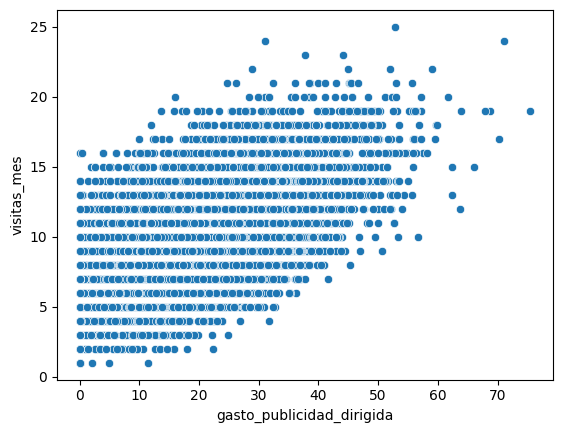

In [67]:
# Visualizar pares de variables con relaciones moderadas o fuertes
sns.scatterplot(data=df, x='gasto_publicidad_dirigida',y='visitas_mes')


<Axes: xlabel='ingreso_anual', ylabel='compras_mes'>

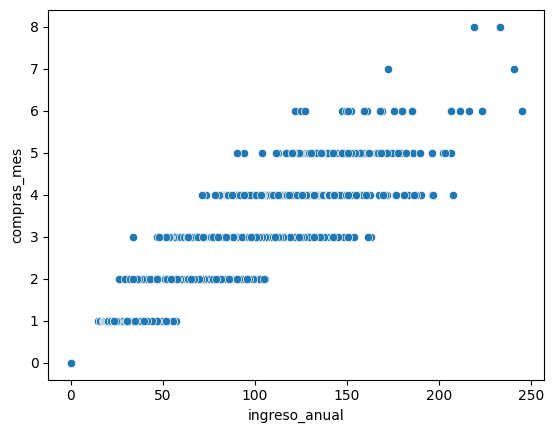

In [68]:
sns.scatterplot(data =df, x='ingreso_anual',y='compras_mes')

**Observaciones iniciales (Scatterplot)**


**gasto_publicidad_dirigida vs visitas_mes**
- Dirección: Positiva. A medida que aumenta el gasto en publicidad dirigida, también tiende a aumentar el número de visitas mensuales.

- Dispersión: Media. Existe una tendencia ascendente, aunque los puntos presentan cierta variabilidad alrededor del patrón.

- Outliers: Se observan algunos clientes con niveles de gasto en publicidad significativamente superiores al resto (por encima de 70), pero no parecen alterar la tendencia general.

- Posible colinealidad: Se evidencia una relación moderada entre ambas variables, consistente con la correlación observada en el heatmap (≈0.58). No parece existir una colinealidad excesiva.-

**ingreso_anual vs compras_mes**

- Dirección: Positiva muy fuerte. A medida que aumenta el número de compras mensuales, el ingreso anual también se incrementa.

- Dispersión: Baja. Los puntos siguen un patrón claramente ascendente, mostrando una relación lineal muy marcada.

- Outliers: Se observan algunos clientes con ingresos anuales elevados (cercanos a 240–250), pero siguen la misma tendencia y no se consideran valores atípicos preocupantes.

- Relación entre las variables: En el gráfico se observa que los clientes que realizan más compras mensuales tienden a generar mayores ingresos anuales. Esto coincide con la correlación de aproximadamente 0,97. Esta relación fuerte no representa, por sí sola, un problema para el análisis.


## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [69]:
# Calcular correlación entre variables relevantes
df['gasto_publicidad_dirigida'].corr(df['visitas_mes'], method='pearson')

np.float64(0.5789472719412829)

In [70]:
# Calcular correlación entre variables relevantes
df['ingreso_anual'].corr(df['compras_mes'],method='pearson')

np.float64(0.9671485435708559)

**Observaciones de correlación**

`gasto_publicidad_dirigida` vs `visitas_mes`
- Dirección: Positiva, ya que el coeficiente de Pearson es 0.579, indicando que ambas variables tienden a aumentar conjuntamente.
- Magnitud: Moderada. La relación existe, pero no es lo suficientemente fuerte como para afirmar que una variable explica completamente el comportamiento de la otra.
- Posible colinealidad: No se observa un problema importante de colinealidad, ya que el coeficiente es inferior a 0.80.

`ingreso_anual` vs `compras_mes`
- Dirección: Positiva, con un coeficiente de Pearson de 0.967, lo que indica que a mayor número de compras mensuales, mayor ingreso anual.
- Magnitud: Muy fuerte. El valor cercano a 1 evidencia una relación lineal casi perfecta entre ambas variables.
- Relación entre las variables: Se observa que los clientes que hacen más compras al mes también tienden a generar mayores ingresos anuales. Esta relación fuerte no representa por sí sola un problema para el análisis. Antes de usar las compras mensuales para predecir el ingreso anual, revisaría cómo se calcularon ambos datos y si esa información estaría disponible al momento de hacer la predicción.



- **En resumen:** los coeficientes de Pearson confirman los patrones observados en las visualizaciones. En particular, compras_mes es la variable con la asociación más fuerte respecto al ingreso_anual, mientras que gasto_publicidad_dirigida mantiene una relación positiva moderada con visitas_mes. Estos resultados respaldan que la frecuencia de compra es el comportamiento más relacionado con la generación de ingresos en la plataforma.

### Punto-biserial

In [71]:


# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr
binarias=['miembro_premium','abandono']
def corr_point_biserial(df, binarias, ingreso_anual):
    for col in binarias:
        coef, p_value = pointbiserialr(df[col],df['ingreso_anual'])
        print (f'\nCorrelacion entre: {col} y {ingreso_anual}')
        print(f'Point-Biserial:{coef:.4f}')
corr_point_biserial(df, binarias,'ingreso_anual')





Correlacion entre: miembro_premium y ingreso_anual
Point-Biserial:0.0931

Correlacion entre: abandono y ingreso_anual
Point-Biserial:-0.0028


**Observaciones Punto-biserial**

`miembro_premium` vs `ingreso_anual`
- Dirección: Positiva (0.0931). Los clientes con membresía premium tienden a presentar un ingreso anual ligeramente mayor.
- Magnitud: Muy baja. La asociación es débil, por lo que la membresía premium, por sí sola, no parece estar fuertemente relacionada con el ingreso anual.

`abandono` vs `ingreso_anual`
- Dirección: Negativa (-0.0028). Los clientes que abandonan la plataforma tienden a presentar un ingreso anual ligeramente menor.
- Magnitud: Prácticamente nula. El coeficiente es muy cercano a cero, indicando que no existe una relación lineal relevante entre el abandono y el ingreso anual.


- **En resumen:** La correlación punto-biserial muestra que ni la membresía premium ni el abandono presentan una asociación fuerte con el ingreso anual. Aunque la membresía premium tiene una relación positiva, esta es muy débil, mientras que el abandono presenta una relación negativa prácticamente inexistente.Los resultados muestran que la membresía premium tiene una relación muy débil con el ingreso anual, mientras que la relación entre abandono e ingreso anual es cercana a cero. En estos datos, las compras mensuales están mucho más relacionadas con el ingreso anual que estas dos variables.

### V de Cramér

In [72]:
# Función para calcular V de Cramér
from scipy.stats import chi2_contingency
def cramer_v (df,tipo_dispositivo,region):
    tabla = pd.crosstab(df['tipo_dispositivo'],df['region'])
    chi2, p_value, dof, expected = chi2_contingency(tabla)
    n= tabla.values.sum()
    v= np.sqrt(chi2/(n*(min(tabla.shape)-1)))
    return v

In [73]:
# Aplicar V de Cramér en variables relevantes


coef_cramer = cramer_v (df,'tipo_dispositivo','region')
print ('\nCorrelación entre: region y tipo dispositivo')
print(f'V de cramer: {coef_cramer:.3f}')




Correlación entre: region y tipo dispositivo
V de cramer: 0.012


El resultado de V de Cramér es aproximadamente 0,012. Esto indica que la región y el tipo de dispositivo tienen una relación muy débil en los datos analizados. Por eso, conocer la región de un cliente aporta poca información sobre el dispositivo que utiliza. Este resultado, por sí solo, no demuestra que las variables sean independientes.


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1 — La frecuencia de compra es el factor más asociado con el ingreso anual

**Evidencia visual:**  El scatterplot entre compras_mes e ingreso_anual muestra una clara tendencia ascendente, con una relación lineal muy marcada y baja dispersión.
**Evidencia numérica:** La correlación de Pearson entre ambas variables es 0.967, indicando una asociación positiva muy fuerte.

**Interpretación**  Los clientes que realizan un mayor número de compras al mes tienden a generar un mayor ingreso anual para la plataforma. Esta es la asociación más fuerte encontrada durante el análisis.


**No podemos afirmar**  No es posible concluir que aumentar el número de compras mensuales cause directamente un mayor ingreso anual, ya que el análisis es correlacional y podrían existir otros factores que influyan en ambas variables.


**Implicación de negocio** NovaRetail+ podría enfocar sus estrategias en incentivar la frecuencia de compra mediante programas de fidelización, promociones o recomendaciones personalizadas, ya que este comportamiento está fuertemente asociado con mayores ingresos.

### Hallazgo 2 — La publicidad dirigida está asociada con un mayor número de visitas

**Evidencia visual:**   El scatterplot entre gasto_publicidad_dirigida y visitas_mes muestra una tendencia positiva, aunque con una dispersión moderada.

**Evidencia numérica:** La correlación de Pearson es 0.579, lo que indica una asociación positiva de magnitud moderada.

**Interpretación** Los clientes expuestos a un mayor gasto en publicidad dirigida tienden a registrar un mayor número de visitas mensuales a la plataforma.


**No podemos afirmar**  No es posible afirmar que incrementar el gasto en publicidad provoque directamente un aumento en las visitas, ya que otros factores podrían influir en este comportamiento.


**Implicación de negocio** La publicidad dirigida podría utilizarse como una herramienta para aumentar el tráfico hacia la plataforma. Sin embargo, sería conveniente evaluar posteriormente si ese incremento en visitas también se traduce en un aumento de compras e ingresos.


## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- La correlación no implica causalidad. Las asociaciones encontradas no permiten concluir que una variable sea la causa directa de otra.
- El análisis se basa en relaciones bivariadas. No se evaluó el efecto conjunto de múltiples variables sobre el ingreso anual.
- No se consideraron variables externas que podrían influir en el comportamiento del cliente, como promociones, estacionalidad, campañas de marketing o competencia.
- Los resultados corresponden únicamente al conjunto de datos analizado, por lo que su generalización a otros periodos o poblaciones debe realizarse con precaución.

### **Próximos pasos**

Probar segmentación adicional
1. Profundizar la segmentación de clientes
Analizar el ingreso anual por región y tipo de dispositivo.
Identificar segmentos de clientes con mayor frecuencia de compra y mayor valor para el negocio.

2. Evaluar estrategias de crecimiento
Analizar si un aumento en las visitas derivadas de publicidad se traduce en un incremento en las compras y en el ingreso anual.
Medir el impacto de programas de fidelización o campañas dirigidas sobre la frecuencia de compra.


# En resumen:
El análisis exploratorio permitió identificar que el comportamiento de compra de los clientes, especialmente la frecuencia de compras mensuales, es el factor con mayor asociación al ingreso anual. En contraste, variables demográficas y categóricas como la región, el tipo de dispositivo, la membresía premium o el abandono mostraron asociaciones débiles. Estos resultados proporcionan una base para orientar futuras estrategias de segmentación y modelos predictivos que apoyen la toma de decisiones en NovaRetail+.